In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning & Metrik
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.metrics import roc_curve, auc

# Pengaturan visualisasi agar keren
sns.set_theme(style="whitegrid")
import warnings
warnings.filterwarnings('ignore')

print("✅ Semua Library Berhasil Dimuat!")

✅ Semua Library Berhasil Dimuat!


In [3]:
print("🚀 MEMUAT DATASET SEPHIA...")
df = pd.read_csv('dataset_skripsi.csv')

print(f"Total Baris: {df.shape[0]}")
print(f"Total Kolom (Fitur): {df.shape[1]}\n")

print("🔍 Pengecekan Missing Values (Data Kosong):")
print(df.isnull().sum())

# Tampilkan 5 data teratas
display(df.head())

🚀 MEMUAT DATASET SEPHIA...
Total Baris: 5000
Total Kolom (Fitur): 11

🔍 Pengecekan Missing Values (Data Kosong):
label                  0
url_length             0
has_ip                 0
count_dash             0
count_at               0
is_https               0
external_link_ratio    0
null_link_ratio        0
has_password_field     0
has_brand_name         0
domain_match           0
dtype: int64


,label,url_length,has_ip,count_dash,count_at,is_https,external_link_ratio,null_link_ratio,has_password_field,has_brand_name,domain_match
0,1,25,1,3,0,1,0.913579,0.757053,0,1,0
1,1,64,0,2,1,0,0.665332,0.652282,1,1,0
2,1,46,0,4,0,1,0.947401,0.465596,1,1,0
3,1,106,1,5,0,1,0.354024,0.079181,0,1,0
4,0,32,0,2,0,1,0.239572,0.028833,1,1,1


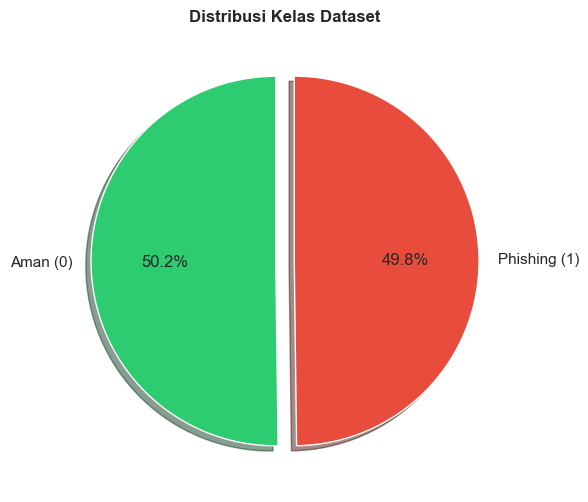

In [4]:
plt.figure(figsize=(6, 6))
labels = ['Aman (0)', 'Phishing (1)']
sizes = df['label'].value_counts().values
colors = ['#2ecc71', '#e74c3c']

plt.pie(sizes, labels=labels, colors=colors, autopct='%1.1f%%', 
        shadow=True, startangle=90, explode=(0.05, 0.05))
plt.title('Distribusi Kelas Dataset', fontweight='bold')
plt.show()

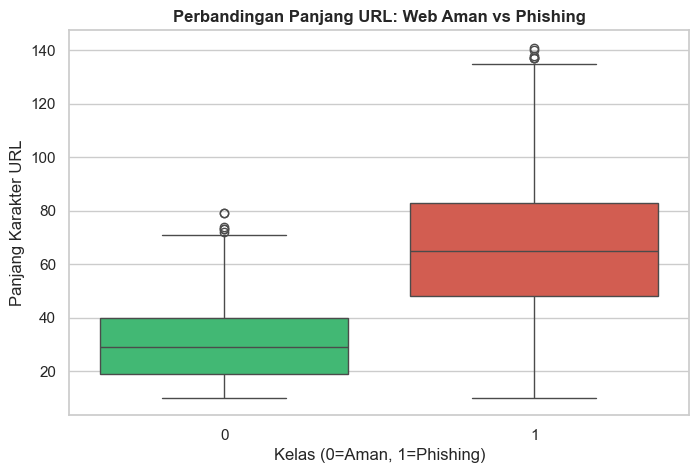

In [5]:
plt.figure(figsize=(8, 5))
sns.boxplot(x='label', y='url_length', data=df, palette=['#2ecc71', '#e74c3c'])
plt.title('Perbandingan Panjang URL: Web Aman vs Phishing', fontweight='bold')
plt.xlabel('Kelas (0=Aman, 1=Phishing)')
plt.ylabel('Panjang Karakter URL')
plt.show()

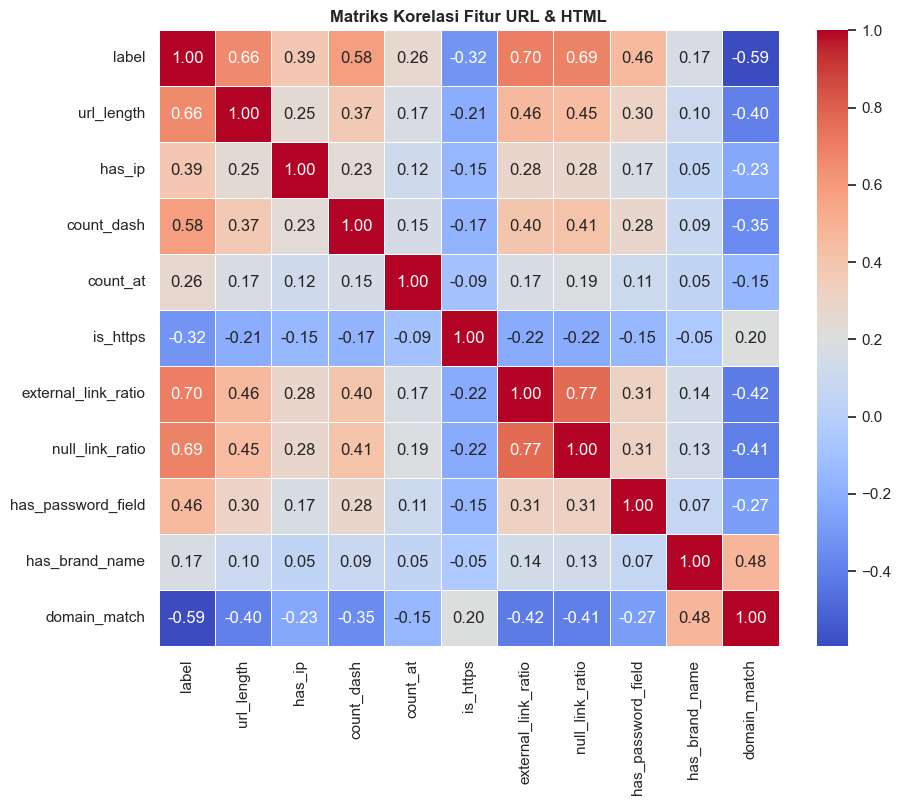

In [6]:
plt.figure(figsize=(10, 8))
corr = df.corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Matriks Korelasi Fitur URL & HTML', fontweight='bold')
plt.show()

In [7]:
X = df.drop(columns=['label'])
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("📊 PEMBAGIAN DATASET Selesai:")
print(f"Data Latih (Training) : {X_train.shape[0]} sampel")
print(f"Data Uji (Testing)    : {X_test.shape[0]} sampel")

📊 PEMBAGIAN DATASET Selesai:
Data Latih (Training) : 4000 sampel
Data Uji (Testing)    : 1000 sampel


In [8]:
print("⏳ Sedang melatih Random Forest, XGBoost, dan Model Ensemble SEPHIA...")

# 1. Random Forest Sendirian
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

# 2. XGBoost Sendirian
xgb = XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42)
xgb.fit(X_train, y_train)
xgb_pred = xgb.predict(X_test)

# 3. Model Utama Kamu (Ensemble Soft Voting)
ensemble = VotingClassifier(estimators=[('rf', rf), ('xgb', xgb)], voting='soft')
ensemble.fit(X_train, y_train)
ensemble_pred = ensemble.predict(X_test)

print("\n🏆 HASIL AKURASI MODEL:")
print(f"1. Akurasi Random Forest : {accuracy_score(y_test, rf_pred)*100:.2f}%")
print(f"2. Akurasi XGBoost       : {accuracy_score(y_test, xgb_pred)*100:.2f}%")
print(f"3. Akurasi ENSEMBLE      : {accuracy_score(y_test, ensemble_pred)*100:.2f}% (Model Terpilih!)")

⏳ Sedang melatih Random Forest, XGBoost, dan Model Ensemble SEPHIA...

🏆 HASIL AKURASI MODEL:
1. Akurasi Random Forest : 99.10%
2. Akurasi XGBoost       : 99.00%
3. Akurasi ENSEMBLE      : 99.10% (Model Terpilih!)


In [ ]:
cm = confusion_matrix(y_test, ensemble_pred)

plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Web Aman (0)', 'Phishing (1)'], 
            yticklabels=['Web Aman (0)', 'Phishing (1)'])
plt.title('Confusion Matrix - Model Ensemble', fontweight='bold')
plt.xlabel('Prediksi Mesin AI')
plt.ylabel('Label Sebenarnya')
plt.show()

print("\n📑 LAPORAN KLASIFIKASI MENDETAIL:")
print(classification_report(y_test, ensemble_pred))

: 

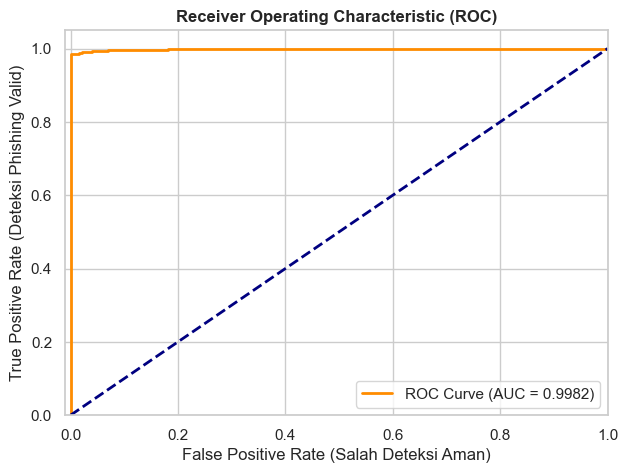

In [10]:
y_prob = ensemble.predict_proba(X_test)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC Curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([-0.01, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (Salah Deteksi Aman)')
plt.ylabel('True Positive Rate (Deteksi Phishing Valid)')
plt.title('Receiver Operating Characteristic (ROC)', fontweight='bold')
plt.legend(loc="lower right")
plt.show()

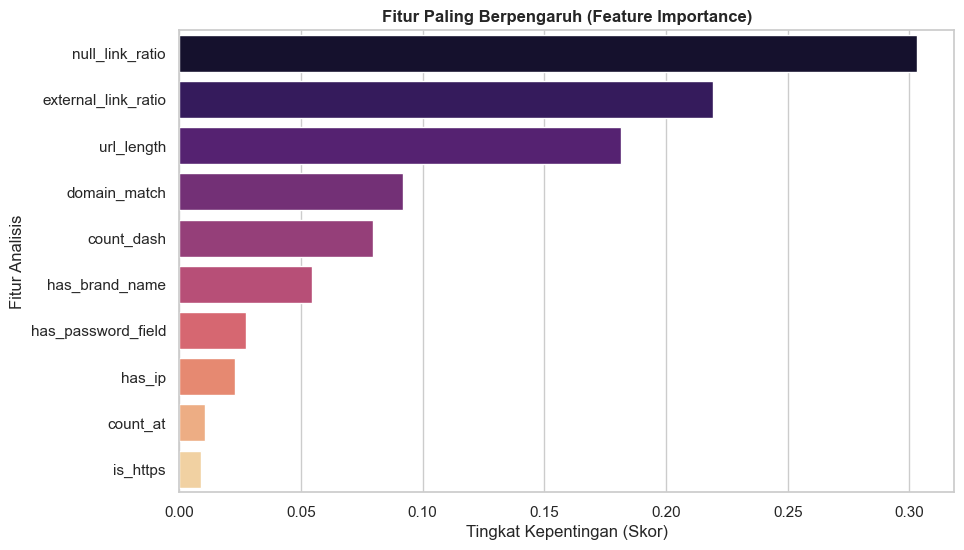

In [11]:
importances = rf.feature_importances_
feature_names = X.columns
indices = np.argsort(importances)[::-1]

plt.figure(figsize=(10, 6))
sns.barplot(x=importances[indices], y=feature_names[indices], palette='magma')
plt.title('Fitur Paling Berpengaruh (Feature Importance)', fontweight='bold')
plt.xlabel('Tingkat Kepentingan (Skor)')
plt.ylabel('Fitur Analisis')
plt.show()